In [38]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(847063)

## Exercício — Simulação da distribuição normal

Considere a densidade da normal padrão,

$$
f(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2},
$$

e, para $x>0$, utilize como distribuição proposta uma exponencial com taxa $1$,

$$
g(x)=e^{-x}, \qquad x\geq 0.
$$

1. Para aplicar o método de rejeição-aceitação, determine a constante

$$
c=\sup_{x>0}\frac{f(x)}{g(x)}.
$$

Para isso, encontre o ponto de máximo da razão $f(x)/g(x)$ e obtenha a expressão da probabilidade de aceitação

$$
\frac{f(x)}{c\,g(x)}.
$$

2. A partir do resultado anterior, implemente em Python um algoritmo de rejeição-aceitação para gerar uma amostra de tamanho $n$ da distribuição de $|N(0,1)|$.

3. Utilize sinais aleatórios independentes, com probabilidades iguais de serem positivos ou negativos, para transformar essa amostra em uma amostra de

$$
N(0,1).
$$

Gere também uma amostra de mesmo tamanho utilizando `numpy.random.normal` e compare as duas distribuições por meio de histogramas.

4. Suponha agora que você saiba gerar $Z\sim N(0,1)$. Como você pode utilizar $Z$ para gerar

$$
X\sim N(\mu,\sigma^2)?
$$

Implemente essa transformação para gerar uma amostra de tamanho $n$ de $N(\mu,\sigma^2)$.

5. Gere também uma amostra de $N(\mu,\sigma^2)$ utilizando `numpy.random.normal` e compare os histogramas das duas amostras.

6. Durante a simulação, registre o número total de propostas geradas e calcule a taxa empírica de aceitação,

$$
\widehat{p}_{\text{aceitação}}
=
\frac{\text{número de valores aceitos}}
{\text{número total de propostas}}.
$$

Compare esse valor com a taxa teórica de aceitação do método,

$$
p_{\text{aceitação}}=\frac{1}{c},
$$

onde $c$ é a constante obtida anteriormente. Os valores observado e esperado são compatíveis?

In [39]:
c = 2*np.exp(1/2)/np.sqrt(2*np.pi)
print(c)


1.315489246958914


In [40]:
def f(x):
  return 2*np.exp(-(x**2)/2)/np.sqrt(2*np.pi)

def g(x):
  return np.exp(-x)


In [41]:
contagem = 0
amostra = []
while len(amostra) < 10_000:
  contagem += 1
  u = np.random.uniform()
  y = (-1) * np.log(np.random.uniform())

  if(u < f(y)/(c*g(y))):
    amostra.append(y)


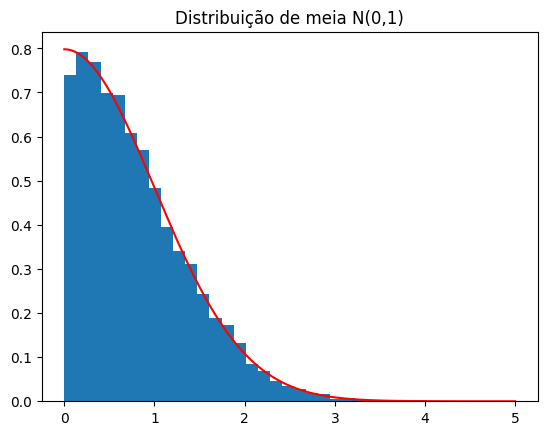

In [42]:
valor = []
for x in np.linspace(0, 5, 10_000):
  valor.append(f(x))

plt.hist(amostra, density=True, bins=30)
plt.plot(np.linspace(0, 5, 10_000), valor, color='red')
plt.title('Distribuição de meia N(0,1)')
plt.show()

In [43]:
for i in range(len(amostra)):
  if(np.random.uniform() < 0.5):
    amostra[i] = -amostra[i]

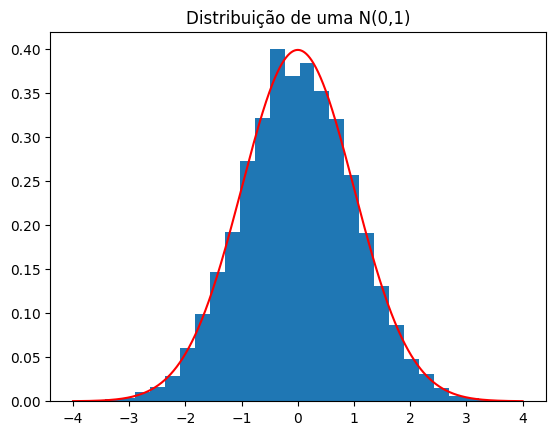

In [44]:
valor = []
for x in np.linspace(-4, 4, 10_000):
  valor.append(f(x)/2)


plt.hist(amostra, density=True, bins=30)
plt.plot(np.linspace(-4, 4, 10_000), valor, color='red')
plt.title('Distribuição de uma N(0,1)')
plt.show()

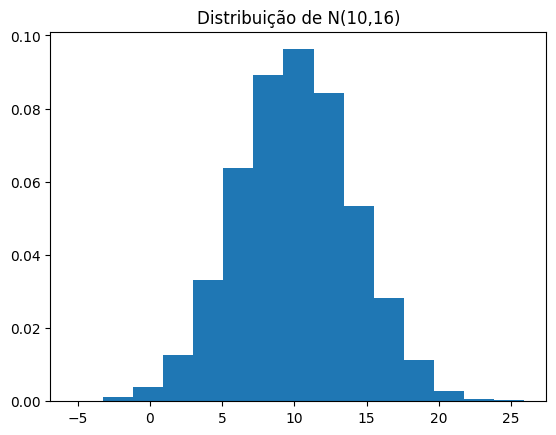

In [45]:
amostra = []
while len(amostra) < 10_000:
  u = np.random.uniform()
  y = (-1) * np.log(np.random.uniform())

  if(u < f(y)/(c*g(y))):
    amostra.append(y)

for i in range(len(amostra)):
  if(np.random.uniform() < 0.5):
    amostra[i] = -amostra[i]

for i in range(len(amostra)):
  amostra[i] = (amostra[i] * 4) + 10

plt.hist(amostra, density=True, bins=15)
plt.title('Distribuição de N(10,16)')
plt.show()

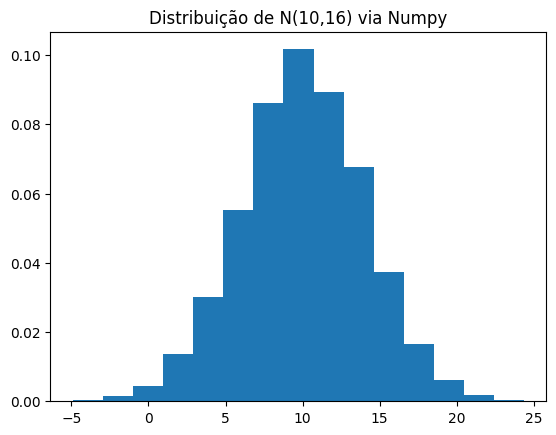

In [46]:
plt.hist(np.random.normal(loc=10, scale=4, size=10_000), density=True, bins=15)
plt.title('Distribuição de N(10,16) via Numpy')
plt.show()

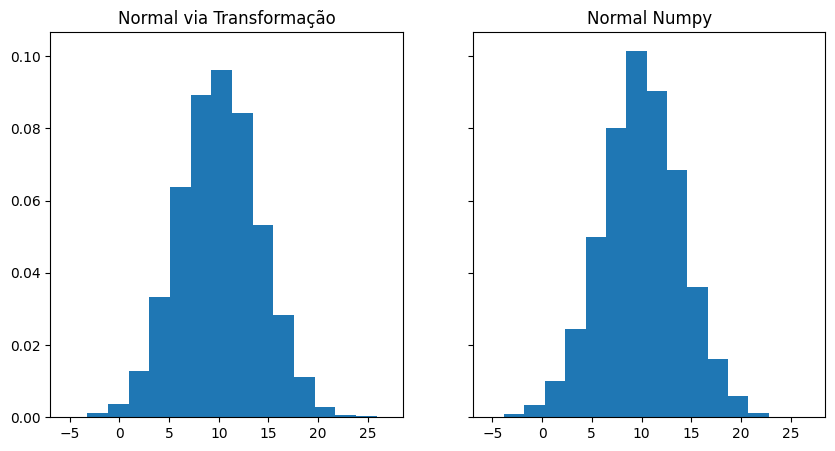

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

ax[0].hist(amostra, density=True, bins=15)
ax[0].set_title('Normal via Transformação')

num = np.random.normal(loc=10, scale=4, size=10_000)

ax[1].hist(num, density=True, bins=15)
ax[1].set_title('Normal Numpy')

plt.show()

In [48]:
aceitacao = 10_000/contagem
print(f"Aceitação obtida: {aceitacao} \nAceitação teorica: {1/c}")

Aceitação obtida: 0.7600516835144789 
Aceitação teorica: 0.7601734505331403
